In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow


In [34]:
df=pd.read_csv("industry.csv")

##EDA

In [35]:
df.shape

(7043, 21)

In [36]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [37]:
df.head().T

,0,1,2,3,4
customerID,7590-VHVEG,5575-GNVDE,3668-QPYBK,7795-CFOCW,9237-HQITU
gender,Female,Male,Male,Male,Female
SeniorCitizen,0,0,0,0,0
Partner,Yes,No,No,No,No
Dependents,No,No,No,No,No
tenure,1,34,2,45,2
PhoneService,No,Yes,Yes,No,Yes
MultipleLines,No phone service,No,No,No phone service,No
InternetService,DSL,DSL,DSL,DSL,Fiber optic
OnlineSecurity,No,Yes,Yes,Yes,No


In [38]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [39]:
df["MonthlyCharges"]=df["MonthlyCharges"].astype(float)

In [40]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

In [41]:
df["TotalCharges"].fillna(0,inplace=True)

C:\Users\Devansh Chauhan\AppData\Local\Temp\ipykernel_13704\2201171674.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/docs/dev/user_guide/migration.html#copy-on-write-cow
  df["TotalCharges"].fillna(0,inplace=True)


0         29.85
1       1889.50
2        108.15
3       1840.75
4        151.65
         ...   
7038    1990.50
7039    7362.90
7040     346.45
7041     306.60
7042    6844.50
Name: TotalCharges, Length: 7043, dtype: float64

In [42]:
df.nunique()

customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6530
Churn                  2
dtype: int64

In [43]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.00,0.000,0.0000,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80


{'bodies': [<matplotlib.collections.FillBetweenPolyCollection at 0x1fa04e6d1c0>],
 'cmaxes': <matplotlib.collections.LineCollection at 0x1fa089a5ac0>,
 'cmins': <matplotlib.collections.LineCollection at 0x1fa08a90f20>,
 'cbars': <matplotlib.collections.LineCollection at 0x1fa08a90770>}

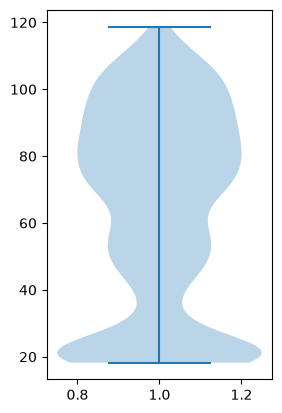

In [44]:
plt.subplot(1,2,1)
plt.violinplot(df["MonthlyCharges"])

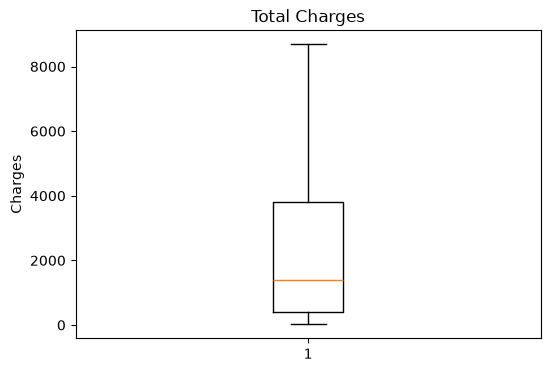

<Figure size 640x480 with 0 Axes>

In [45]:
plt.figure(figsize=(6, 4))
plt.boxplot(df["TotalCharges"].dropna())
plt.title("Total Charges")
plt.ylabel("Charges")
plt.show()
plt.tight_layout()

<Axes: >

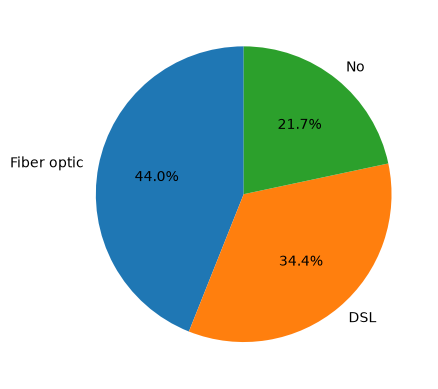

In [46]:
df["InternetService"].value_counts().plot(kind="pie",autopct="%1.1f%%",startangle=90)

Text(0, 0.5, 'No of Senior Citizens')

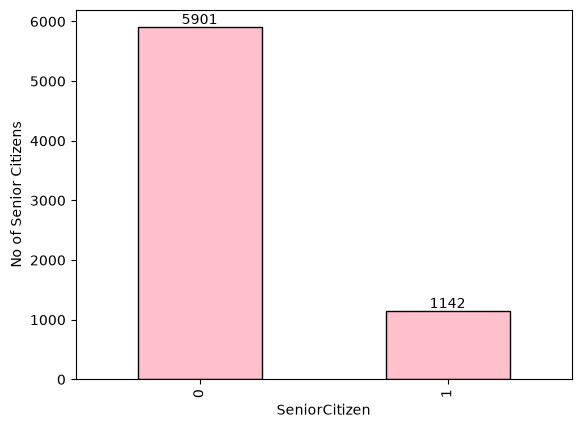

In [58]:
ax=df["SeniorCitizen"].value_counts().plot(kind="bar",color="pink",edgecolor="black")
ax.bar_label(ax.containers[0])
plt.ylabel("No of Senior Citizens")

Text(0, 0.5, 'NO OF COUNTS')

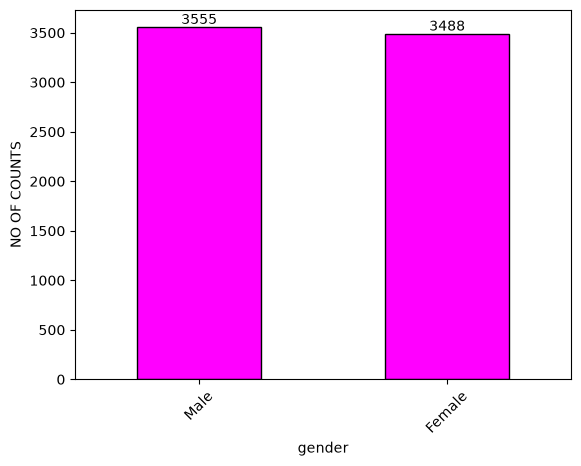

In [48]:
ax=df["gender"].value_counts().plot(kind="bar",color="magenta",edgecolor="black")
ax.bar_label(ax.containers[0])
plt.xticks(rotation=45)
plt.ylabel("NO OF COUNTS")

Text(0, 0.5, 'No of People')

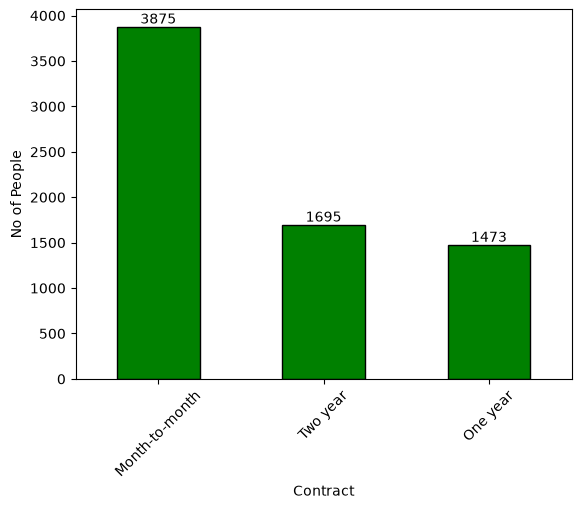

In [49]:
ax=df["Contract"].value_counts().plot(kind="bar",color="green",edgecolor="black")
plt.xticks(rotation=45)
ax.bar_label(ax.containers[0])
plt.ylabel("No of People")

([0, 1, 2, 3],
 [Text(0, 0, 'Electronic check'),
  Text(1, 0, 'Mailed check'),
  Text(2, 0, 'Bank transfer (automatic)'),
  Text(3, 0, 'Credit card (automatic)')])

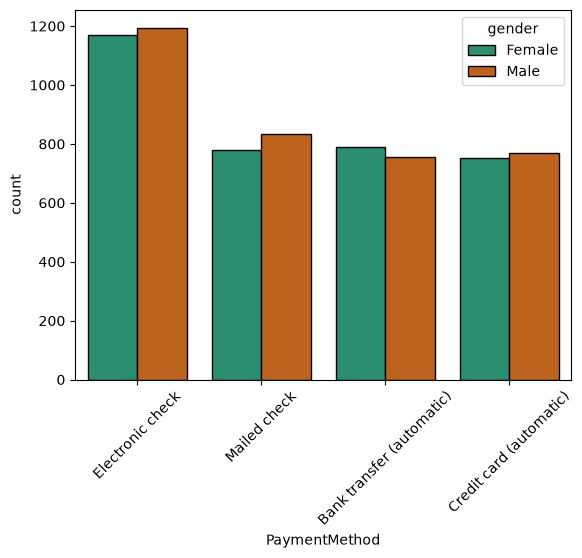

In [50]:
sns.countplot(data=df,x="PaymentMethod",hue="gender",palette="Dark2",edgecolor="black")
plt.xticks(rotation=45)


Text(0, 0.5, 'Total_Charges')

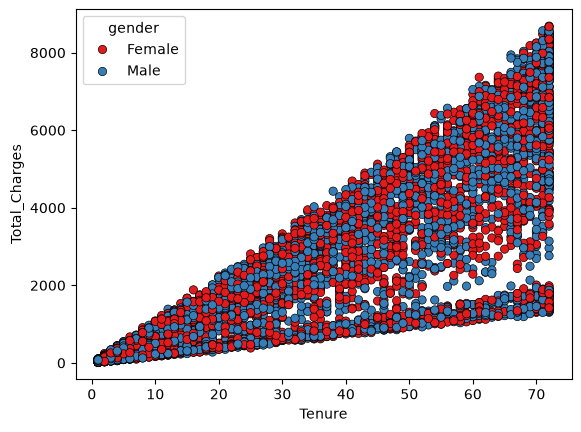

In [51]:
sns.scatterplot(data=df, x="tenure", y="TotalCharges", hue="gender", palette="Set1", edgecolor="black")
plt.xlabel("Tenure")
plt.ylabel("Total_Charges")

<Axes: >

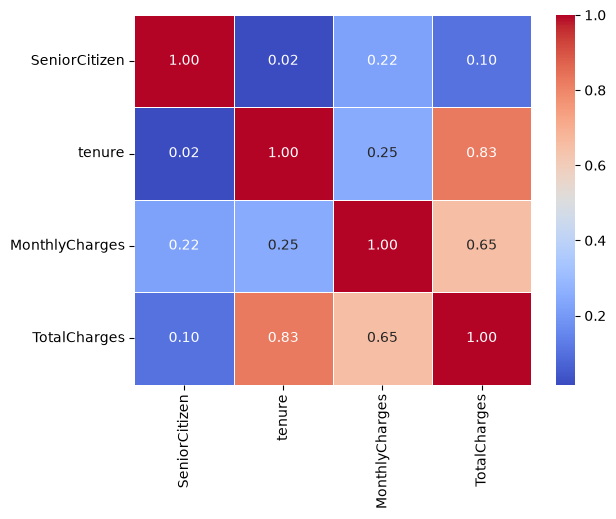

In [52]:
sns.heatmap(df.corr(numeric_only=True),annot=True,cmap="coolwarm",linewidths=0.5,fmt=".2f")

#SUMMARY :-

### 1-There is no outlier in Monthly and Total charges.
### 2-Fibre Optic Provide Highest InterService with 44% Whereas DSl Provide Internet Service about 34.3%.
### 3-DataSet carries Senior Citizen About 1/5th amount of Total Citizen in Dataset.
### 4-Ratio of Male User and Female Owner is Almost Same.
### 5-Peoples Have a Contract of Month Wise is almost 3times as comapare to the people haveing contact of 2 or 3 year.
### 6- As the Tenure Inreases Monthly and Total payment also increases Linearly.  

In [59]:
df.to_csv("Cleaned.csv",index=False)